# PUSL 3205 – Lab 3: Tiny Transformer Language Model (v2 – BPE tokenizer, bigger model)
Trains a GPT-style decoder on **roneneldan/TinyStories** with a **subword (BPE) tokenizer**, more data, mixed precision and a larger model.


Improvements over the character-level baseline: BPE tokens (words as units), 50k stories, ~10M parameters, longer context, fused attention + fp16, lr warm-up/decay, top-p sampling.

In [ ]:
!pip install -q datasets tokenizers gradio matplotlib

In [ ]:
import math, json, random, time
from dataclasses import dataclass, asdict

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
use_amp = device == "cuda"
print("Using device:", device)
torch.manual_seed(1337); random.seed(1337)

Using device: cuda


## 1. Load and explore the dataset

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

...

data/validation-00000-of-00001-869c898b5(…): reconstructing file:   0%|          |  0.00B / 9.99MB            

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 2119719
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 21990
    })
})

--- Story 0 ---
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

To...

--- Story 1 ---
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park when he saw a big tree. The tree had many leaves that were falling. Beep liked how the leaves fall and wanted to play with them. Beep drove under the

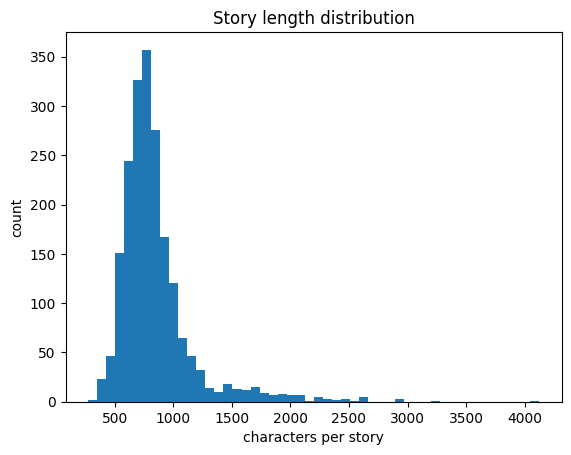

In [ ]:
from datasets import load_dataset

ds = load_dataset("roneneldan/TinyStories")
print(ds)

for i in range(3):
    print(f"\n--- Story {i} ---\n{ds['train'][i]['text'][:400]}...")

lens = [len(ds["train"][i]["text"]) for i in range(2000)]
words = [len(ds["train"][i]["text"].split()) for i in range(2000)]
print(f"\nChars per story (first 2000): min={min(lens)} mean={sum(lens)/len(lens):.0f} max={max(lens)}")
print(f"Words per story: mean={sum(words)/len(words):.0f}")

plt.hist(lens, bins=50); plt.xlabel("characters per story"); plt.ylabel("count")
plt.title("Story length distribution"); plt.show()

## 2. Preprocess: larger subset + BPE tokenizer
A 4096-token BPE vocabulary is trained on the subset. `<eos>` marks the end of each story.

In [ ]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

N_TRAIN, N_VAL = 50000, 2000
train_texts = ds["train"].select(range(N_TRAIN))["text"]
val_texts   = ds["validation"].select(range(N_VAL))["text"]

bpe = Tokenizer(models.BPE())
bpe.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe.decoder = decoders.ByteLevel()
trainer = trainers.BpeTrainer(vocab_size=4096, special_tokens=["<eos>"],
                              initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
bpe.train_from_iterator(train_texts, trainer)
bpe.save("tokenizer.json")


class BPETokenizer:
    def __init__(self, tk):
        self.tk = tk
        self.vocab_size = tk.get_vocab_size()
        self.eos_id = tk.token_to_id("<eos>")
    def encode(self, s): return self.tk.encode(s).ids
    def decode(self, ids): return self.tk.decode(ids)


tok = BPETokenizer(bpe)
print("vocab size:", tok.vocab_size)
ids = tok.encode("Once upon a time, there was a little girl named Lily.")
print(ids); print([bpe.id_to_token(i) for i in ids])


def encode_corpus(texts):
    out = []
    for enc in bpe.encode_batch(texts):
        out += enc.ids + [tok.eos_id]
    return torch.tensor(out, dtype=torch.long)


train_data = encode_corpus(train_texts)
val_data   = encode_corpus(val_texts)
print("train tokens:", len(train_data), "| val tokens:", len(val_data))

val_chars = sum(len(t) for t in val_texts)
chars_per_token = val_chars / len(val_data)
print(f"avg characters per token: {chars_per_token:.2f}")

vocab size: 4096
[427, 441, 259, 397, 12, 398, 282, 259, 396, 445, 495, 359, 14]
['Once', 'Ġupon', 'Ġa', 'Ġtime', ',', 'Ġthere', 'Ġwas', 'Ġa', 'Ġlittle', 'Ġgirl', 'Ġnamed', 'ĠLily', '.']
train tokens: 11356695 | val tokens: 399129
avg characters per token: 3.99


## 3. Prepare training data (next-token prediction)
Input `x = tokens[i : i+T]`, target `y = tokens[i+1 : i+T+1]`.

In [ ]:
def get_batch(data, block_size, batch_size):
    ix = torch.randint(len(data) - block_size - 1, (batch_size,))
    x = torch.stack([data[i:i + block_size] for i in ix])
    y = torch.stack([data[i + 1:i + block_size + 1] for i in ix])
    if device == "cuda":
        return x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)
    return x.to(device), y.to(device)

x, y = get_batch(train_data, 12, 1)
print("x:", x[0].tolist()); print("y:", y[0].tolist())
print("x text:", repr(tok.decode(x[0].tolist())))
print("y text:", repr(tok.decode(y[0].tolist())))

x: [1815, 265, 328, 12, 334, 787, 12, 304, 372, 436, 2309, 748]
y: [265, 328, 12, 334, 787, 12, 304, 372, 436, 2309, 748, 419]
x text: ' bite and said, "Mom, it\'s too salty'
y text: ' and said, "Mom, it\'s too salty."'


## 4. Build the Transformer architecture
Token + positional embeddings, masked multi-head self-attention (fused kernel), feed-forward, residuals, pre-LayerNorm.

In [ ]:
@dataclass
class Config:
    vocab_size: int = 0
    block_size: int = 256     # context length
    n_layer: int = 6
    n_head: int = 6
    n_embd: int = 384
    dropout: float = 0.1


class CausalSelfAttention(nn.Module):
    """Masked (causal) multi-head self-attention."""
    def __init__(self, cfg):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0
        self.n_head = cfg.n_head
        self.qkv = nn.Linear(cfg.n_embd, 3 * cfg.n_embd)
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd)
        self.attn_p = cfg.dropout
        self.resid_drop = nn.Dropout(cfg.dropout)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q, k, v = [t.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) for t in (q, k, v)]
        # softmax(QK^T / sqrt(d)) V with a causal mask, computed by a fused kernel
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True,
                                           dropout_p=self.attn_p if self.training else 0.0)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_drop(self.proj(y))


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(cfg.n_embd, 4 * cfg.n_embd), nn.GELU(),
            nn.Linear(4 * cfg.n_embd, cfg.n_embd), nn.Dropout(cfg.dropout))
    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """Pre-LayerNorm transformer block with residual connections."""
    def __init__(self, cfg):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(cfg.n_embd), nn.LayerNorm(cfg.n_embd)
        self.attn, self.ff = CausalSelfAttention(cfg), FeedForward(cfg)
    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # residual 1
        x = x + self.ff(self.ln2(x))     # residual 2
        return x


class TinyTransformer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.n_embd)   # token embeddings
        self.pos_emb = nn.Embedding(cfg.block_size, cfg.n_embd)   # positional embeddings
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.Sequential(*[Block(cfg) for _ in range(cfg.n_layer)])
        self.ln_f = nn.LayerNorm(cfg.n_embd)
        self.head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight                    # weight tying
        self.apply(self._init)
        # scaled init for residual output projections (keeps activations stable in deeper nets)
        for name, p in self.named_parameters():
            if name.endswith("proj.weight") or name.endswith("net.2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layer))

    @staticmethod
    def _init(m):   # Step 5: parameter initialisation
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))
        x = self.ln_f(self.blocks(x))
        logits = self.head(x)
        loss = None if targets is None else F.cross_entropy(
            logits.float().view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens=300, temperature=0.8, top_k=40, top_p=0.95, eos_id=None):
        self.eval()
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.cfg.block_size:])
            logits = logits[:, -1, :].float() / max(temperature, 1e-6)
            if top_k:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = float("-inf")
            if top_p < 1.0:                                   # nucleus sampling
                sl, si = torch.sort(logits, descending=True)
                probs = F.softmax(sl, dim=-1)
                remove = (torch.cumsum(probs, dim=-1) - probs) > top_p
                sl = sl.masked_fill(remove, float("-inf"))
                logits = torch.full_like(logits, float("-inf")).scatter(1, si, sl)
            nxt = torch.multinomial(F.softmax(logits, dim=-1), 1)
            idx = torch.cat([idx, nxt], dim=1)
            if eos_id is not None and nxt.item() == eos_id:
                break
        return idx

## 5. Initialize the model, loss function and optimizer

In [ ]:
cfg = Config(vocab_size=tok.vocab_size)        # ~10M parameters
model = TinyTransformer(cfg).to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters())/1e6:.2f}M")
# Loss: cross-entropy (inside forward). Optimizer: AdamW + OneCycle LR schedule (created in train()).

Parameters: 12.32M


## 6–7. Train the model and monitor loss

In [ ]:
@torch.no_grad()
def estimate_loss(model, data, block_size, batch_size, iters=50):
    model.eval()
    losses = []
    for _ in range(iters):
        x, y = get_batch(data, block_size, batch_size)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            losses.append(model(x, y)[1].item())
    model.train()
    return sum(losses) / len(losses)


def train(model, train_data, val_data, epochs=10, steps_per_epoch=600, batch_size=64, lr=1e-3):
    block_size = model.cfg.block_size
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr, total_steps=epochs * steps_per_epoch, pct_start=0.05)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    history = {"train": [], "val": []}
    model.train()
    t0 = time.time()
    for ep in range(epochs):
        running = 0.0
        for _ in range(steps_per_epoch):
            x, y = get_batch(train_data, block_size, batch_size)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                _, loss = model(x, y)                     # forward + cross-entropy
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()                 # backpropagation
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)                        # parameter update
            scaler.update()
            sched.step()
            running += loss.item()
        tr = running / steps_per_epoch
        va = estimate_loss(model, val_data, block_size, batch_size)
        history["train"].append(tr); history["val"].append(va)
        print(f"epoch {ep+1:2d}/{epochs}  train {tr:.4f}  val {va:.4f}  perplexity {math.exp(va):.2f}  [{time.time()-t0:.0f}s]")
    return history


def plot_history(history, title="Loss curves"):
    ep = range(1, len(history["train"]) + 1)
    plt.figure(figsize=(6, 4))
    plt.plot(ep, history["train"], label="train")
    plt.plot(ep, history["val"], label="validation")
    plt.xlabel("epoch"); plt.ylabel("cross-entropy loss (per token)"); plt.title(title)
    plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

epoch  1/10  train 3.7971  val 2.6686  perplexity 14.42  [88s]
epoch  2/10  train 2.4242  val 2.2732  perplexity 9.71  [188s]
epoch  3/10  train 2.1668  val 2.1311  perplexity 8.42  [287s]
epoch  4/10  train 2.0361  val 2.0325  perplexity 7.63  [387s]
epoch  5/10  train 1.9424  val 1.9656  perplexity 7.14  [487s]
epoch  6/10  train 1.8707  val 1.9141  perplexity 6.78  [586s]
epoch  7/10  train 1.8107  val 1.8879  perplexity 6.61  [686s]
epoch  8/10  train 1.7665  val 1.8511  perplexity 6.37  [786s]
epoch  9/10  train 1.7345  val 1.8480  perplexity 6.35  [885s]
epoch 10/10  train 1.7247  val 1.8380  perplexity 6.28  [985s]


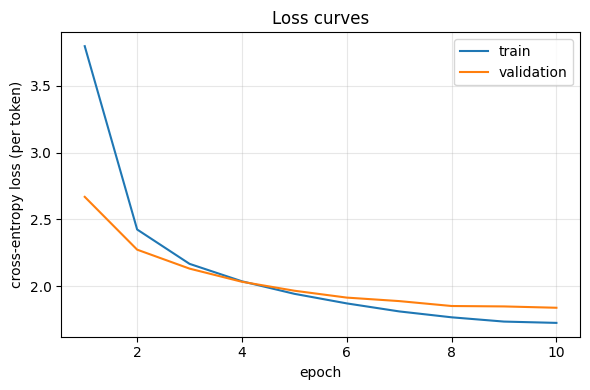

In [ ]:
history = train(model, train_data, val_data, epochs=10, steps_per_epoch=600)   # 6000 steps
plot_history(history)

## 8. Evaluate: validation loss and perplexity

In [ ]:
val_loss = estimate_loss(model, val_data, cfg.block_size, 64, iters=200)
print(f"Validation loss (per token): {val_loss:.4f}")
print(f"Perplexity (per token):      {math.exp(val_loss):.2f}")

# Compare with the character-level baseline (1.225 nats/char, ppl 3.40):
loss_per_char = val_loss / chars_per_token
print(f"Validation loss per character: {loss_per_char:.4f}  (perplexity per character: {math.exp(loss_per_char):.2f})")

Validation loss (per token): 1.8333
Perplexity (per token):      6.25
Validation loss per character: 0.4596  (perplexity per character: 1.58)


## 9. Generate stories

In [ ]:
def sample_text(model, tok, prompt="Once upon a time", n=250, temperature=0.8, top_k=40, top_p=0.95):
    ids = torch.tensor([tok.encode(prompt)], dtype=torch.long, device=device)
    out = model.generate(ids, n, temperature, top_k, top_p, eos_id=tok.eos_id)
    return tok.decode(out[0].tolist())

print(sample_text(model, tok, "Once upon a time", n=300))

Once upon a time, there was a little boy named Timmy. Timmy loved to play with his toy cars and trucks. One day, Timmy's dad made a big pile of wood on the ground. Timmy thought it was very cool.

As Timmy was playing with his car, he noticed that the wood were not working. He asked his dad, "What's wrong, Daddy?" His dad said, "I'm just making a big pile of wood." Timmy felt guilty for not listening to his dad.

But then, Timmy's dad came outside and saw that Timmy was upset. "What's wrong, Timmy?" he asked. Timmy told his dad that he wanted to play with his toy cars. His dad said, "Don't worry, Timmy. I'll help you fix it." Timmy was happy to hear that and they worked together to fix the wood. Timmy learned that it's important to listen to his dad's advice and not play with the wood again.


In [ ]:
# Effect of sampling settings (n = number of TOKENS generated)
for t, p in [(0.5, 0.9), (0.8, 0.95), (1.1, 1.0)]:
    print(f"\n===== temperature {t}, top_p {p} =====")
    print(sample_text(model, tok, "One day, a little girl named Mia", n=200, temperature=t, top_p=p))


===== temperature 0.5, top_p 0.9 =====
One day, a little girl named Mia went to the park with her mom. They saw a big slide and Mia wanted to try it. She asked her mom, "Can I go on the slide, please?" Her mom said, "Yes, but be careful not to go too far."

Mia and her mom went to the slide. Mia was very happy. She climbed up the ladder and slid down the slide. She laughed and laughed. She was having so much fun.

After playing, Mia and her mom went home. Mia felt happy and tired. She said to her mom, "I had fun at the park, Mom. I had a fun day at the park." Her mom smiled and said, "Me too, Mia. I had fun at the park."

===== temperature 0.8, top_p 0.95 =====
One day, a little girl named Mia found a shiny coin on the ground. She picked it up and held it in her hand.

Mia wanted to show her special coin to her friend, so she went to her friend, Max. Max asked if he could have it. Mia said yes, and they both held the coin tightly.

They kept walking, and soon they reached a big tree. 

## 10. Experiment with model settings
Each run uses a smaller base model (n_embd=256, 250 steps per epoch) so the 7 runs finish in roughly 30–40 minutes on a T4. Reduce `settings` if short on time.


=== layers=2 heads=4 epochs=6 ===
epoch  1/6  train 4.5810  val 3.4624  perplexity 31.89  [11s]
epoch  2/6  train 3.2245  val 2.9737  perplexity 19.56  [23s]
epoch  3/6  train 2.9295  val 2.7470  perplexity 15.60  [36s]
epoch  4/6  train 2.7783  val 2.6423  perplexity 14.05  [48s]
epoch  5/6  train 2.6938  val 2.5747  perplexity 13.13  [59s]
epoch  6/6  train 2.6549  val 2.5774  perplexity 13.16  [70s]

=== layers=4 heads=2 epochs=6 ===
epoch  1/6  train 4.5481  val 3.4396  perplexity 31.18  [18s]
epoch  2/6  train 3.2059  val 2.9480  perplexity 19.07  [36s]
epoch  3/6  train 2.8813  val 2.7384  perplexity 15.46  [55s]
epoch  4/6  train 2.7086  val 2.5738  perplexity 13.12  [74s]
epoch  5/6  train 2.5978  val 2.5030  perplexity 12.22  [92s]
epoch  6/6  train 2.5560  val 2.5062  perplexity 12.26  [111s]

=== layers=4 heads=4 epochs=3 ===
epoch  1/3  train 4.3527  val 3.4450  perplexity 31.34  [19s]
epoch  2/3  train 3.2107  val 3.0110  perplexity 20.31  [38s]
epoch  3/3  train 2.9790  

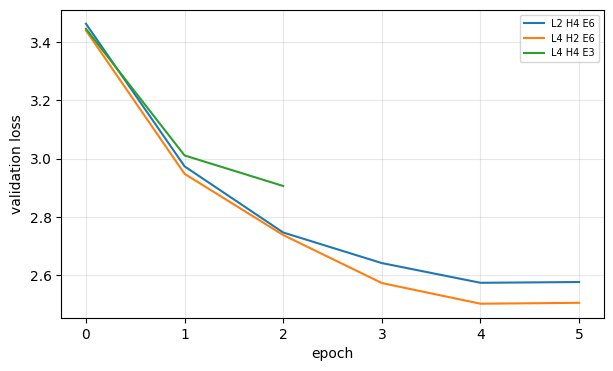


[layers=2 heads=4 epochs=6]
Once upon a time, there was a little girl called Lily. She loved to eat apples, but she always made her feel good.

One day, Lily's mom asked her to help make them look nice. Lily was happy. She said, "That's great, Lily. I'll help you?"

Lily was so excited to have some vegetables. She got some butter and jam on her mom and put it in the kitchen. Lily was so happy and she asked her to help her mom if she could buy some fruit. Lily was happy to have some bread.

When they finished, Lily

[layers=4 heads=2 epochs=6]
Once upon a time, there was a little girl named Lily. She loved to draw pictures on her draw and write on it. One day, she found a picture of a picture of a picture of a picture of a picture of a pictures of a picture of her friends. 

Lily wanted to draw a picture of the picture with her. Her friend asked her what was, and she replied, "It's a picture of a picture for you. Can you?" 

Her friend replied, "Sure, you can help me?" 

Lily was very 

In [ ]:
settings = [  # (n_layer, n_head, epochs)
    (2, 4, 6),      # vary depth
    (4, 2, 6),               # vary heads
    (4, 4, 3),                # vary training length
]

results = []
for n_layer, n_head, epochs in settings:
    print(f"\n=== layers={n_layer} heads={n_head} epochs={epochs} ===")
    c = Config(vocab_size=tok.vocab_size, n_layer=n_layer, n_head=n_head, n_embd=256)
    m = TinyTransformer(c).to(device)
    h = train(m, train_data, val_data, epochs=epochs, steps_per_epoch=250)
    results.append(dict(layers=n_layer, heads=n_head, epochs=epochs,
                        params=sum(p.numel() for p in m.parameters()),
                        val_loss=h["val"][-1], ppl=math.exp(h["val"][-1]),
                        sample=sample_text(m, tok, n=120), history=h))
    del m; torch.cuda.empty_cache()

print("\nlayers heads epochs    params  val_loss    ppl")
for r in results:
    print(f"{r['layers']:6d} {r['heads']:5d} {r['epochs']:6d} {r['params']:9d}  {r['val_loss']:.3f}  {r['ppl']:7.2f}")

plt.figure(figsize=(7, 4))
for r in results:
    plt.plot(r["history"]["val"], label=f"L{r['layers']} H{r['heads']} E{r['epochs']}")
plt.xlabel("epoch"); plt.ylabel("validation loss"); plt.legend(fontsize=7); plt.grid(alpha=.3); plt.show()

for r in results:
    print(f"\n[layers={r['layers']} heads={r['heads']} epochs={r['epochs']}]\n{r['sample']}")

## 11. Save the trained model (parameters + configuration + tokenizer)

In [ ]:
torch.save({"state_dict": model.state_dict(), "config": asdict(model.cfg)}, "tiny_transformer_bpe.pt")
print("saved -> tiny_transformer_bpe.pt and tokenizer.json")

# To download from Colab:
# from google.colab import files
# files.download("tiny_transformer_bpe.pt"); files.download("tokenizer.json")

saved -> tiny_transformer_bpe.pt and tokenizer.json


In [ ]:
# Reload for future generation
ck = torch.load("tiny_transformer_bpe.pt", map_location=device)
loaded = TinyTransformer(Config(**ck["config"])).to(device)
loaded.load_state_dict(ck["state_dict"]); loaded.eval()
tok2 = BPETokenizer(Tokenizer.from_file("tokenizer.json"))
print(sample_text(loaded, tok2, "Once upon a time", n=300))

Once upon a time, there was a little girl named Lily. She had a favorite jacket that she loved to wear. One day, Lily's friend came over to play. Lily showed her jacket and said, "Look, Mommy! It's my favorite jacket!"

Her friend replied, "Wow, that's cool! Can I wear it?"

Lily was so happy and said, "Yes, let's take it outside and play." They put on the jacket and went outside to play. They ran and played with the jacket, but they got lost.

Lily's friend, Timmy, saw the jacket and said, "Oh no, what happened to my jacket?"

Lily said, "Oh no, I'm sorry. I didn't mean to break it."

Timmy said, "It's okay. I'll help you find it." They searched everywhere, but it was nowhere to be found.

Finally, they found the jacket under the sun. Timmy was so happy and said, "Thank you for helping me find my jacket."

Lily smiled and said, "You're welcome, Timmy. I'm glad we found it."


## Optional: Gradio chat window

In [ ]:
import gradio as gr

def respond(prompt, temperature, top_p, length):
    return sample_text(loaded, tok2, prompt or "Once upon a time", int(length), temperature, 40, top_p)

demo = gr.Interface(
    fn=respond,
    inputs=[gr.Textbox(label="Story prompt", value="Once upon a time"),
            gr.Slider(0.2, 1.5, 0.8, label="Temperature"),
            gr.Slider(0.5, 1.0, 0.95, label="Top-p"),
            gr.Slider(50, 400, 250, step=10, label="Max new tokens")],
    outputs=gr.Textbox(label="Generated story", lines=12),
    title="Tiny Transformer Story Generator")
demo.launch(share=True)   # share=True gives a public link in Colab

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://86a7172a78bff26a6b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Discussion: mechanisms that improve performance
- **Subword (BPE) tokenization** – the model starts from word pieces instead of single characters, so capacity goes into grammar and story structure rather than spelling; also shortens sequences, so the same context window covers more text.
- **Self-attention** – each position attends directly to earlier positions, capturing long-range dependencies (e.g. a character's name several sentences back).
- **Causal masking** – blocks access to future tokens, so training matches generation.
- **Multi-head attention** – several heads learn different relations in parallel.
- **Positional embeddings** – attention ignores order on its own, so position must be injected.
- **Residual connections + pre-LayerNorm** – give gradients a direct path and stabilise activations, letting deeper models train with higher learning rates.
- **Scaled initialisation** – smaller residual-branch weights keep the signal stable as depth grows.
- **Feed-forward layers + GELU** – per-token non-linear capacity beyond attention mixing.
- **More data and longer training** – the largest single factor; the baseline was limited by training time, not overfitting.
- **AdamW, LR warm-up/decay, gradient clipping, weight decay** – faster, more stable convergence and regularisation.
- **Mixed precision (fp16) and fused attention** – more training steps in the same wall-clock time.
- **Weight tying** – shares embedding and output matrices, cutting parameters.
- **Temperature, top-k and top-p sampling** – trade diversity against coherence at generation time.